# Predicting experimental treatment effects
## Ashokkumar archive


## How Ashokkumar et al. made the predictions

- Each prompt combined a study introduction, a demographic profile, the experimental stimulus, and the outcome question with its response scale. The profiles described age, gender, race, education, ideology and party affiliation. The model was asked to predict the described person's response.
- For each condition and outcome in the primary archive, the authors used **120 prompts**. They sampled **five model responses per prompt and averaged those five responses**.
- They then averaged across prompts, using population weights to account for oversampled demographic groups. Differences between the weighted condition means gave predicted treatment effects. Our files use their GPT-4 predictions.
- These profiles are not digital twins of the human respondents. In this notebook, we additionally average the supplied predictions within party and condition, then assign each human respondent the corresponding group prediction. Section 2 explains this workshop step.

Source: Ashokkumar et al., main article and Methods, “LLM prompting”; Supplementary Information, “LLM prompting” and analysis of the primary archive. [Paper and supplement](https://doi.org/10.1038/s41586-026-10742-x) · [Replication archive](https://codeocean.com/capsule/9843791/tree/v1).


### The example in this notebook

Does information about racial discrimination change perceptions of discrimination and support for pro-Black policies? Can an LLM predict those changes?

Our example is **Beliefs about Racial Discrimination and Support for Pro-Black Policies**, by Ingar Haaland and Christopher Roth, published in *The Review of Economics and Statistics* 105(1), 40–53 (2023). The study description follows their accepted manuscript, Section II, and their original outcome definitions. [Published paper](https://doi.org/10.1162/rest_a_01036) · [Open accepted manuscript](https://wrap.warwick.ac.uk/id/eprint/151133/).

The human responses and GPT-4 simulations come from the [Ashokkumar et al. replication archive](https://codeocean.com/capsule/9843791/tree/v1), study `Haaland874`. We use existing predictions. No model account or coding agent is required.

Open this notebook inside the downloaded repository. The data and predictions are included; follow the setup instructions in the repository README.

## Before you run the analysis

Complete the setup in the repository README first. Run the following cell only if you need to install the analysis packages in this notebook’s Python environment. The first installation needs an internet connection. Then run the analysis cells in order.

In [ ]:
%pip install -q numpy pandas matplotlib openpyxl https://github.com/Michael-Howes/ppi_py/archive/2dc0ceede320ddf81b4d1050df04fbd1f48bd31b.zip

## 1. The information treatment

Participants read about a study of racial discrimination in hiring. The researchers sent equivalent resumes with white-sounding or Black-sounding names. Everyone learns that resumes with white-sounding names needed ten applications, on average, to receive one callback. Participants then estimate the corresponding number for Black-sounding names.

- The **information treatment** reveals that Black-sounding names needed fifteen applications per callback. It explains that employers were 50 percent more likely to call back applicants with white-sounding names.
- The **control group** proceeds to the outcome questions without receiving that result.

We ask whether the model captures treatment effects on perceptions and self-reported policy views.

| Archive outcome | Meaning | Scale |
|---|---|---|
| Racial Discrimination perception | Perceived seriousness of racial discrimination against Black people in the labor market | 1, not a problem at all, to 5, a very serious problem |
| Affirmative action: Preference | Support for giving qualified Black candidates preference over equally qualified white candidates in getting a job | 1, strongly oppose, to 5, strongly support |
| Affirmative action: Assistance | Support for giving qualified Black candidates assistance in getting a job | 1, strongly oppose, to 5, strongly support |

Haaland and Roth measured these three outcomes separately. We use the same three measures here. The original paper also includes incentivized beliefs, donations and other outcomes. Those are not all available as human/model outcome pairs here. In particular, perceived seriousness is not the paper's quantitative belief-updating measure or a verified manipulation check.

## Load the workshop data

Give `pd.read_csv` the **CSV filename**, not a study title or PDF name. `haaland_responses.csv` is our prepared workshop extract; it is not an original archive filename. It contains three outcomes from `Haaland874`. To change outcomes, use the outcome choice below.

The archive-wide response file contains other studies in one table. Later you can select them using the `study` and `outcome` columns. `effects.csv`, retained as an optional resource, is a renamed copy of the authors’ published `fig1_panelA.csv`.

Keep the repository folders together. The next cell finds the included files automatically when you open the notebook from the repository root or its `notebooks/` folder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ppi_py import classical_ols_ci, ppi_ols_ci
import sys

%matplotlib inline

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = str(ROOT / "data/workshop/ashokkumar") + "/"
sys.path.insert(0, str(ROOT / "scripts"))
from workshop_helpers import ppi_correlation, effective_sample_size
SEED = 20261013

data = pd.read_csv(DATA + "haaland_responses.csv")
print(data.groupby("outcome").size())
data.head()

No event loop hook running.
outcome
Affirmative action: Assistance      1529
Affirmative action: Preference      1532
Racial Discrimination perception    1534
dtype: int64


,outcome,source_row,treated,Y,Yhat
0,Racial Discrimination perception,1,1,2.0,1.295182
1,Racial Discrimination perception,2,1,4.0,1.295182
2,Racial Discrimination perception,3,1,1.0,1.713471
3,Racial Discrimination perception,4,1,1.0,1.295182
4,Racial Discrimination perception,5,1,3.0,1.713471


## 2. How the predictions are assigned

Ashokkumar et al. supply separate human responses and simulated personas. These are not person-specific digital twins. Ashokkumar et al. oversampled some demographic groups, including Black profiles, to study subgroup differences. Their weights adjust how much each simulated profile contributes to an average, according to the subgroup’s share of the US population. We use those supplied weights when averaging GPT-4 predictions within each outcome, treatment condition and party group. A human respondent receives the prediction for their party and condition. This extra averaging within party groups is our workshop construction. Ashokkumar et al. used weighted averages across profiles to predict condition means. The supplied prediction for each profile already averages repeated model responses.

No observed human outcome is used to construct these predictions. People in the same party and condition share a prediction. Predictive accuracy therefore concerns this particular party-group predictor, not the best accuracy achievable with all demographic information.

`source_row` identifies a row within an original outcome table. It is not a verified identifier across outcomes. We analyze outcomes separately. Missing human outcomes or predictions are excluded; the data guide records exclusions. All estimates below use the original 1–5 scales.

### Discussion · Does averaging predictions change the PPI assumptions?

A group average can serve as a prediction rule. Here the rule assigns the same weighted prediction to people in the same party and treatment condition. We apply that exact rule to both the labeled and unlabeled people.

- The two sets of people must come from the same target population, with comparable covariate distributions within each treatment condition. For this illustration, we randomly choose whose human responses we pretend to have collected within each condition. Both sets contain real respondents from the same experiment.
- Keep the prediction rule fixed and independent of the human outcomes used for correction. If you fit or tune the predictor using those outcomes, sample splitting or cross-fitting is needed.
- The simulated profiles used to build the rule need not themselves be a perfect population sample for PPI’s correction to work. Inaccurate profile weights can weaken the predictor. They are not weights that make our human sample representative of all Americans.
- Simply appending simulated personas drawn from a different population would not satisfy the same-distribution assumption. For a new unlabeled sample, we would need the appropriate distribution of party and other variables used by the analysis, as well as the same prediction rule. Correcting a sampling mismatch requires additional methods.

Repeated group predictions do not create new independent people. Our unlabeled sample consists of respondents whose human answers we pretend have not been collected. The inference concerns complete cases. This is how we apply the common-population requirement discussed by Broska et al. and Angelopoulos et al. to this group-average predictor.


In [2]:
outcome = "Affirmative action: Assistance"  # Strongest PPI correlation among the three Haaland outcomes.
selected = data[data["outcome"] == outcome]
Y = selected["Y"].to_numpy()
Yhat = selected["Yhat"].to_numpy()
treated = selected["treated"].to_numpy()
X = np.column_stack([np.ones(len(Y)), treated])  # Intercept, then treatment.
print(selected.groupby("treated")[["Y", "Yhat"]].mean().round(3))

             Y   Yhat
treated              
0        2.552  2.214
1        2.526  2.130


## 3. Compare treatment effects across outcomes

Every effect is the treatment mean minus the control mean. A positive effect indicates increased perceived seriousness or policy support. The human intervals below are approximate 95% intervals for independent respondents. We show predicted effects as points because repeated group predictions are not independent model draws.

In [3]:
rows = []
for name, d in data.groupby("outcome"):
    design = np.column_stack([np.ones(len(d)), d["treated"]])
    lower, upper = classical_ols_ci(design, d["Y"].to_numpy(), alpha=.05)
    means = d.groupby("treated")["Yhat"].mean()
    rows.append([name, (lower[1] + upper[1]) / 2, lower[1], upper[1], means[1] - means[0]])
summary = pd.DataFrame(rows, columns=["outcome", "human", "lower", "upper", "model"])
print(summary.round(3).to_string(index=False))

                         outcome  human  lower  upper  model
  Affirmative action: Assistance -0.025 -0.130  0.079 -0.083
  Affirmative action: Preference  0.031 -0.079  0.140 -0.212
Racial Discrimination perception -0.171 -0.290 -0.051 -0.119


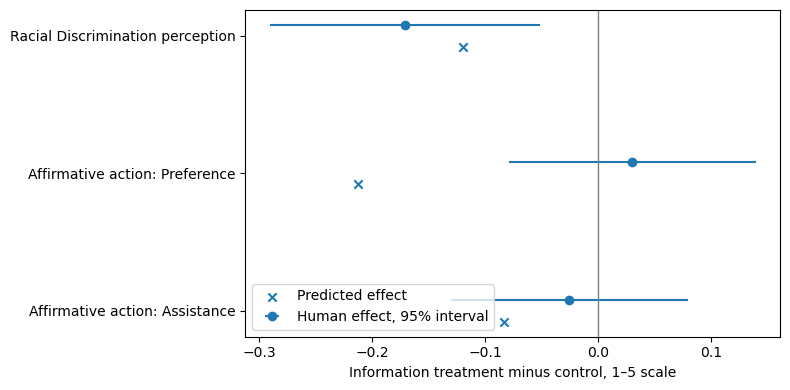

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(summary))
ax.errorbar(summary.human, y + .08, xerr=(summary.upper - summary.lower) / 2,
            fmt="o", label="Human effect, 95% interval")
ax.scatter(summary.model, y - .08, marker="x", label="Predicted effect")
ax.set_yticks(y, summary.outcome)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Information treatment minus control, 1–5 scale")
ax.legend()
plt.tight_layout()
plt.show()

**Reading this plot**

- The information treatment lowers perceived seriousness of discrimination by about 0.17 scale points in the human data. The model predicts a smaller decrease, about 0.12 points.
- The human effects on the two policy outcomes are close to zero; both intervals include zero. This does not prove that the effects are exactly zero.
- The model predicts lower support for both policies. Its clearest discrepancy is hiring preference: roughly −0.21 points, compared with +0.03 in humans.
- The bars show uncertainty in the human estimates. The model crosses describe effects of the party-group predictions; they are not independent observations with individual-level uncertainty bars.

The information corrects beliefs that can initially overestimate or underestimate discrimination. It need not raise perceived seriousness for everyone. This is a comparison of available outcomes, not a reproduction of the paper’s full belief-updating analysis.

## 4. Mixed subjects with prediction-powered inference

Compare three estimates: model responses only, a smaller human sample, and the human sample combined with predictions through PPI. We use the `ppi_py` package for the regression intervals and PPI tuning.

With an intercept and a binary treatment, regression coefficient 1 is the treatment effect. Coefficient 0 is the intercept. For illustration, pretend we have collected human responses from only half the people in each condition. We select that half with a fixed random seed. For the other half, we use only predictions. We do not evaluate against their human answers.

The model-only interval concerns model responses across sampled people. It does not establish that the predicted human effect is correct. PPI corrects prediction bias using observed human responses.

In [5]:
rng = np.random.default_rng(SEED)
labeled = np.zeros(len(Y), dtype=bool)
for arm in [0, 1]:
    indices = np.flatnonzero(treated == arm)
    chosen = rng.choice(indices, size=len(indices) // 2, replace=False)
    labeled[chosen] = True
print("Human responses collected in this illustration:", labeled.sum())
print("People with predictions only:", (~labeled).sum())

Human responses collected in this illustration: 764
People with predictions only: 765


In [6]:
X_human, Y_human, Yhat_human = X[labeled], Y[labeled], Yhat[labeled]
X_silicon, Yhat_silicon = X[~labeled], Yhat[~labeled]
n, N = labeled.sum(), (~labeled).sum()

silicon = classical_ols_ci(X_silicon, Yhat_silicon, alpha=.05)
humans = classical_ols_ci(X_human, Y_human, alpha=.05)
mixed = ppi_ols_ci(X_human, Y_human, Yhat_human, X_silicon, Yhat_silicon,
                   alpha=.05, coord=1)

table = pd.DataFrame([[ci[0][1], ci[1][1]] for ci in [silicon, humans, mixed]],
                     index=["Silicon subjects", "Human subjects", "Mixed subjects"],
                     columns=["lower", "upper"])
table["estimate"] = (table.lower + table.upper) / 2  # These intervals are symmetric.
table["width"] = table.upper - table.lower
print(table.round(3))

                  lower  upper  estimate  width
Silicon subjects -0.136  0.015    -0.061  0.151
Human subjects   -0.234  0.062    -0.086  0.296
Mixed subjects   -0.220  0.070    -0.075  0.290


Mixed / human interval width: 0.979


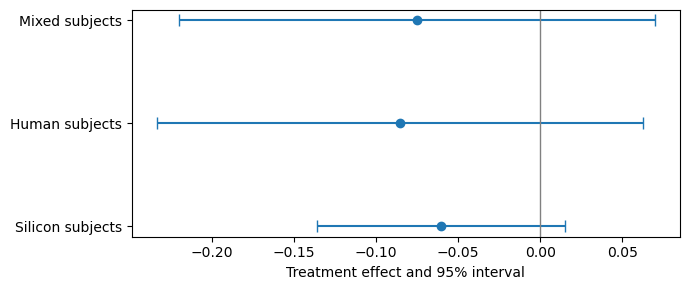

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(table.estimate, np.arange(3), xerr=table.width / 2, fmt="o", capsize=4)
ax.set_yticks(np.arange(3), table.index)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Treatment effect and 95% interval")
plt.tight_layout()
plt.show()
print("Mixed / human interval width:", round(table.loc["Mixed subjects", "width"] / table.loc["Human subjects", "width"], 3))

## 5. PPI correlation and effective sample size

The **PPI correlation** measures how useful these predictions are for the treatment coefficient. It is not the ordinary correlation between human and predicted answers.

Think of **effective sample size** as the number of human observations giving the same precision as a combined sample of observations and predictions.

`ppi_ols_power` also returns an effective sample size for an optimized future design. Here we keep our actual numbers of labeled and unlabeled people fixed, so we do not need costs or a budget. The small helper below gets the PPI correlation from the package and uses it to calculate approximate effective sample size for these sample sizes.

This is a large-sample approximation with optimal weighting, not the realized precision gain from this particular split. Compare it with the interval widths above.

In [8]:
rho = ppi_correlation(X_human, Y_human, Yhat_human)
ess = effective_sample_size(rho, n, N)
print("PPI correlation:", round(rho, 3))
print("Human responses:", n, "| Unlabeled people:", N)
print("Approximate effective sample size:", round(ess, 1))
print("Gain over the human sample (%):", round(100 * (ess / n - 1), 1))

PPI correlation: 0.294
Human responses: 764 | Unlabeled people: 765
Approximate effective sample size: 798.4
Gain over the human sample (%): 4.5


## 6. Where across the archive are predictions useful?

We have prepared PPI correlations and approximate effective sample size gains for all evaluable pairs of conditions in the response archive. For each pair, we compute the package’s PPI correlation and ask what gain it implies for a design that splits the available people approximately in half between labeled and unlabeled samples. It uses all complete responses as pilot data.

In [9]:
archive = pd.read_csv(DATA + "archive_ppi.csv")
coverage = pd.read_csv(DATA + "archive_ppi_coverage.csv")
print("Source studies:", coverage.study.nunique())
print("Studies with matched responses:", coverage.loc[coverage.complete_rows > 0, "study"].nunique())
print(archive.status.value_counts())
usable = archive[archive.status == "ok"]
print("Evaluable pairs:", len(usable), "in", usable.study.nunique(), "studies")
usable[["study", "outcome", "ppi_corr", "effective_n", "ess_gain_percent"]].head()

Source studies: 71
Studies with matched responses: 69
status
ok    1675
Name: count, dtype: int64
Evaluable pairs: 1675 in 69 studies


,study,outcome,ppi_corr,effective_n,ess_gain_percent
0,AnsonBRIEF60,blue_collar_positivity,0.021581,194.045304,0.023352
1,AnsonBRIEF60,economy_positivity,0.004555,194.002018,0.001040
2,Blair1131,Approve_Handling,0.013495,99.009016,0.009107
3,Blair1131,Approve_Handling,0.101218,101.522616,0.517442
4,Blair1131,Approve_Handling,-0.073218,95.255327,0.268765


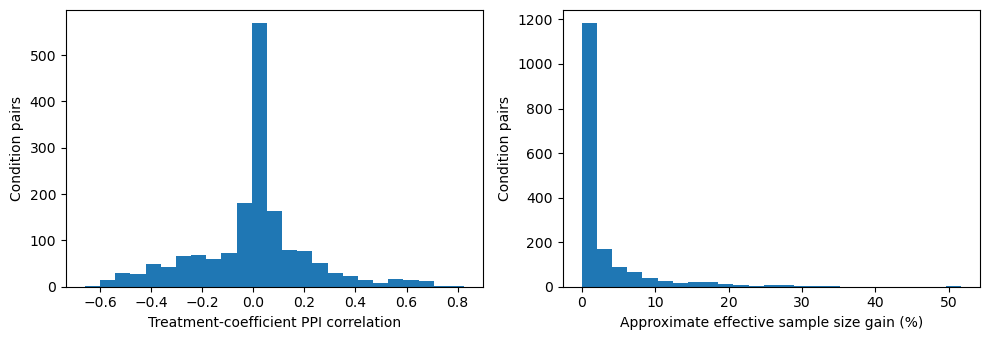

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(usable.ppi_corr, bins=25)
axes[0].set_xlabel("Treatment-coefficient PPI correlation")
axes[1].hist(usable.ess_gain_percent, bins=25)
axes[1].set_xlabel("Approximate effective sample size gain (%)")
for ax in axes:
    ax.set_ylabel("Condition pairs")
plt.tight_layout()
plt.show()

**Try another comparison**

Choose a study and outcome from the table. List its condition names, then choose two conditions. The cell below recomputes the result from the included response data. Change the number of unlabeled people to see how the effective sample size changes.

The Haaland correlation may differ from section 5 because this section uses all complete people as pilot data rather than only the revealed half.

In [11]:
responses = pd.read_csv(DATA + "archive_responses.csv.gz")
study_id = "Haaland874"
outcome_name = "Racial Discrimination perception"
d = responses[(responses.study == study_id) & (responses.outcome == outcome_name)]
print("Available conditions:", d.condition.unique())

Available conditions: ['TREATMENT' 'CONTROL']


In [12]:
reference, comparison = "CONTROL", "TREATMENT"
d = d[d.condition.isin([reference, comparison])]
X_pilot = np.column_stack([np.ones(len(d)), (d.condition == comparison).astype(int)])
rho = ppi_correlation(X_pilot, d.Y.to_numpy(), d.Yhat.to_numpy())
n = len(d) // 2
N = len(d) - n  # Try N = 5 * n instead.
ess = effective_sample_size(rho, n, N)
print("PPI correlation:", round(rho, 3))
print("Approximate effective sample size:", round(ess, 1))
print("Gain over n human responses (%):", round(100 * (ess / n - 1), 1))

PPI correlation: 0.203
Approximate effective sample size: 783.1
Gain over n human responses (%): 2.1


## Share one result

- Which outcomes or condition pairs have useful PPI correlations?
- Does a good prediction of the average treatment effect also imply a useful PPI correlation?
- How does the number of unlabeled people change the effective sample size gain?
- Does a pattern persist when each study, rather than each pair, gets equal weight?

Show one plot, one finding, one limitation and one question to investigate next. The data guide explains how predictions were matched and which comparisons are available. Package implementation: [Michael Howes’s ppi_py](https://github.com/Michael-Howes/ppi_py).